# Tugas Kelompok Berbasis Kasus 02: Unsupervised Learning (Clustering)

**Nama Kelompok:** centroid

**Anggota:**
1. Andika Dinata (123140096)
2. Ardiansyah Fernando (123140102)
3. Yudhistira Novianto Kurniawan (123140138)

## Rencana Eksperimen

| Dataset | Algoritma 1 (Modul 05) | Algoritma 2 (Modul 06) |
|---|---|---|
| Credit Card | K-Means | Gaussian Mixture Model (GMM) |
| NYSE | Agglomerative Clustering | DBSCAN |

In [ ]:
%pip install -q kagglehub

import glob
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import kagglehub
from IPython.display import display
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import MinMaxScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}

Bagian ini menyiapkan alat untuk mengunduh data, mengolah tabel, membuat grafik, dan menjalankan clustering. Tampilan tabel dan grafik juga diatur agar hasilnya lebih mudah dibaca.


## Part A: Credit Card (K-Means dan Gaussian Mixture Model)

### A1. Mengunduh dataset

In [ ]:
cc_dir = kagglehub.dataset_download("arjunbhasin2013/ccdata")
cc_path = glob.glob(os.path.join(cc_dir, "*.csv"))[0]
cc_raw = pd.read_csv(cc_path)

print(cc_path)
print(cc_raw.shape)
display(cc_raw.head())
cc_raw.info()

Using Colab cache for faster access to the 'ccdata' dataset.
/kaggle/input/ccdata/CC GENERAL.csv
(8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   object 
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHA

Data Credit Card diunduh dari Kaggle, lalu diperiksa ukuran, contoh isi, dan kelengkapan datanya. Setiap baris mewakili satu pemegang kartu kredit, sedangkan kolomnya menggambarkan saldo, penggunaan kartu, pembayaran, dan informasi terkait lainnya. Kolom CUST_ID hanya berfungsi sebagai identitas nasabah.


### A2. Memproses data agar bersih

In [ ]:
cc_features = cc_raw.drop(columns=["CUST_ID"])
cc_missing = cc_features.isnull().sum()
print(cc_missing[cc_missing > 0])
cc_imputed = cc_features.fillna(cc_features.median())

cc_log_columns = [
    "BALANCE",
    "PURCHASES",
    "ONEOFF_PURCHASES",
    "INSTALLMENTS_PURCHASES",
    "CASH_ADVANCE",
    "CASH_ADVANCE_TRX",
    "PURCHASES_TRX",
    "CREDIT_LIMIT",
    "PAYMENTS",
    "MINIMUM_PAYMENTS",
]
cc_logged = cc_imputed.copy()
cc_logged[cc_log_columns] = np.log1p(cc_logged[cc_log_columns])

cc_skew = pd.DataFrame()
cc_skew["before_log"] = cc_imputed[cc_log_columns].skew()
cc_skew["after_log"] = cc_logged[cc_log_columns].skew()
display(cc_skew.round(2))

cc_scaler = MinMaxScaler()
cc_scaled = cc_scaler.fit_transform(cc_logged)

cc_pca_model = PCA(n_components=3, random_state=0)
cc_pca = cc_pca_model.fit_transform(cc_scaled)

print(cc_scaled.shape)
print(cc_pca_model.explained_variance_ratio_.round(3))

CREDIT_LIMIT          1
MINIMUM_PAYMENTS    313
dtype: int64


,before_log,after_log
BALANCE,2.39,-0.86
PURCHASES,8.14,-0.76
ONEOFF_PURCHASES,10.05,0.19
INSTALLMENTS_PURCHASES,7.30,-0.02
CASH_ADVANCE,5.17,0.26
CASH_ADVANCE_TRX,5.72,0.94
PURCHASES_TRX,4.63,0.03
CREDIT_LIMIT,1.52,-0.10
PAYMENTS,5.91,-1.78
MINIMUM_PAYMENTS,13.85,0.27


(8950, 17)
[0.465 0.156 0.129]


Pada tahap preprocessing, CUST_ID dihapus karena hanya berfungsi sebagai identitas dan tidak mencerminkan perilaku keuangan, sedangkan missing value pada CREDIT_LIMIT dan MINIMUM_PAYMENTS diisi dengan median karena lebih tahan terhadap outlier. Transformasi log diterapkan pada beberapa fitur, seperti jumlah belanja dan pembayaran, agar selisih nilai yang sangat besar tidak terlalu mendominasi hasil. Selanjutnya, MinMaxScaler menyamakan skala seluruh fitur ke rentang 0–1 agar pembobotan setiap variabel lebih adil. Clustering tetap menggunakan 17 fitur, sedangkan PCA dengan tiga komponen hanya digunakan untuk visualisasi.

### A3. Mencari nilai K

Finished k = 2
Finished k = 3
Finished k = 4
Finished k = 5
Finished k = 6
Finished k = 7
Finished k = 8
Finished k = 9
Finished k = 10


,k,kmeans_silhouette,kmeans_davies_bouldin,gmm_silhouette,gmm_davies_bouldin
0,2,0.3234,1.2661,0.2914,1.3824
1,3,0.2699,1.5509,0.2156,1.9649
2,4,0.2632,1.4748,0.2435,1.6050
3,5,0.2801,1.3779,0.2416,1.5702
4,6,0.2708,1.4180,0.2225,1.6401
5,7,0.2665,1.3963,0.2196,2.1779
6,8,0.2675,1.3939,0.1378,2.2137
7,9,0.2612,1.4029,0.1949,2.4606
8,10,0.2637,1.4308,0.1924,2.4817


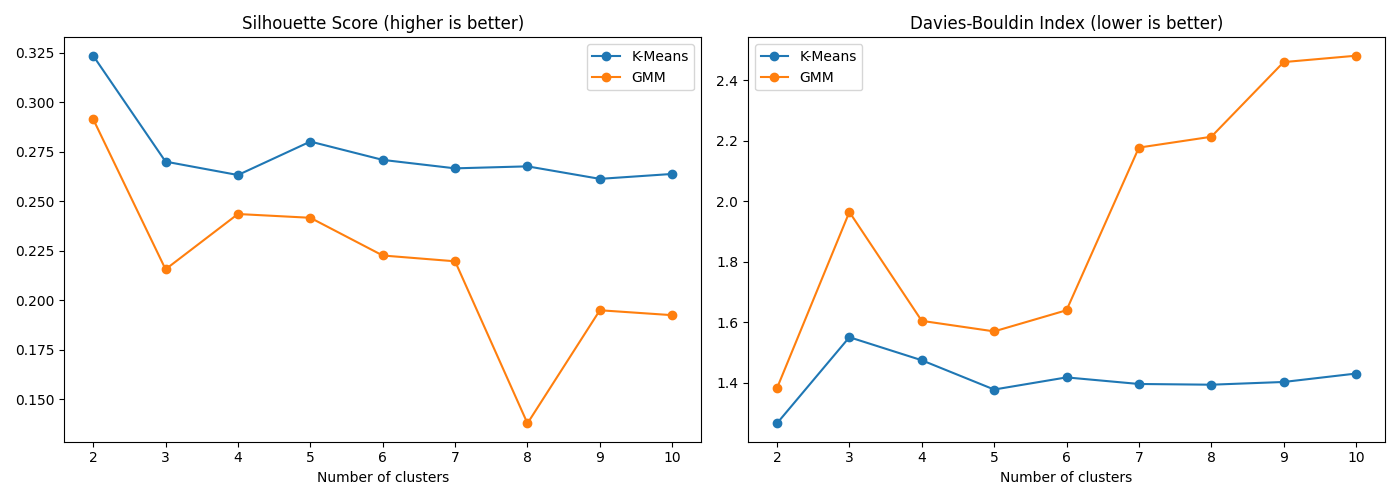

Best K-Means k: 2
Best GMM n_components: 2


In [ ]:
k_values = range(2, 11)

kmeans_silhouette_scores = []
kmeans_davies_bouldin_scores = []
gmm_silhouette_scores = []
gmm_davies_bouldin_scores = []

for k in k_values:
    kmeans_candidate = KMeans(n_clusters=k, init="k-means++", max_iter=300, n_init=10, random_state=0)
    kmeans_candidate_labels = kmeans_candidate.fit_predict(cc_scaled)
    kmeans_silhouette_scores.append(silhouette_score(cc_scaled, kmeans_candidate_labels))
    kmeans_davies_bouldin_scores.append(davies_bouldin_score(cc_scaled, kmeans_candidate_labels))

    gmm_candidate = GaussianMixture(n_components=k, covariance_type="full", n_init=10, max_iter=200, random_state=42)
    gmm_candidate_labels = gmm_candidate.fit_predict(cc_scaled)
    gmm_silhouette_scores.append(silhouette_score(cc_scaled, gmm_candidate_labels))
    gmm_davies_bouldin_scores.append(davies_bouldin_score(cc_scaled, gmm_candidate_labels))

    print("Finished k =", k)

cc_search_results = pd.DataFrame()
cc_search_results["k"] = list(k_values)
cc_search_results["kmeans_silhouette"] = kmeans_silhouette_scores
cc_search_results["kmeans_davies_bouldin"] = kmeans_davies_bouldin_scores
cc_search_results["gmm_silhouette"] = gmm_silhouette_scores
cc_search_results["gmm_davies_bouldin"] = gmm_davies_bouldin_scores
display(cc_search_results.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(k_values, kmeans_silhouette_scores, marker="o", label="K-Means")
axes[0].plot(k_values, gmm_silhouette_scores, marker="o", label="GMM")
axes[0].set_title("Silhouette Score (higher is better)")
axes[1].plot(k_values, kmeans_davies_bouldin_scores, marker="o", label="K-Means")
axes[1].plot(k_values, gmm_davies_bouldin_scores, marker="o", label="GMM")
axes[1].set_title("Davies-Bouldin Index (lower is better)")
for axis in axes:
    axis.set_xlabel("Number of clusters")
    axis.legend()
plt.tight_layout()
plt.show()

best_kmeans_k = k_values[np.argmax(kmeans_silhouette_scores)]
best_gmm_k = k_values[np.argmax(gmm_silhouette_scores)]
print("Best K-Means k:", best_kmeans_k)
print("Best GMM n_components:", best_gmm_k)

kmeans_model = KMeans(n_clusters=best_kmeans_k, init="k-means++", max_iter=300, n_init=10, random_state=0)
gmm_model = GaussianMixture(n_components=best_gmm_k, covariance_type="full", n_init=10, max_iter=200, random_state=42)

K-Means dan GMM dicoba dengan jumlah cluster antara 2 hingga 10. Pilihan akhirnya didasarkan pada Silhouette Score tertinggi, yaitu ukuran seberapa jelas suatu cluster terpisah dari cluster lain. Keduanya memilih dua cluster, dengan skor 0,3234 untuk K-Means dan 0,2914 untuk GMM. Ukuran pembanding Davies-Bouldin Index, yang semakin kecil semakin baik, juga mencapai nilai terendah pada dua cluster untuk masing-masing model. Dengan demikian, kedua ukuran tersebut mendukung pilihan yang sama dalam percobaan ini.


### A4. Melatih model

In [ ]:
kmeans_labels = kmeans_model.fit_predict(cc_scaled)
gmm_labels = gmm_model.fit_predict(cc_scaled)

print("K-Means inertia:", round(kmeans_model.inertia_, 2))
print("GMM converged:", gmm_model.converged_)

print("K-Means cluster sizes")
print(pd.Series(kmeans_labels).value_counts().sort_index())
print("GMM cluster sizes")
print(pd.Series(gmm_labels).value_counts().sort_index())

K-Means inertia: 6725.21
GMM converged: True
K-Means cluster sizes
0    4232
1    4718
Name: count, dtype: int64
GMM cluster sizes
0    3912
1    5038
Name: count, dtype: int64


Setelah dijalankan pada seluruh 8.950 nasabah, K-Means membagi data menjadi cluster berisi 4.232 dan 4.718 orang, sedangkan GMM menghasilkan cluster berisi 3.912 dan 5.038 orang. Tidak ada cluster yang hanya berisi segelintir nasabah. Proses GMM juga selesai dengan status converged, sehingga hasilnya dapat dilanjutkan ke tahap evaluasi.


### A5. Mengevaluasi model

K-Means (k=2): silhouette=0.3234, davies_bouldin=1.2661
GMM (n_components=2): silhouette=0.2914, davies_bouldin=1.3824


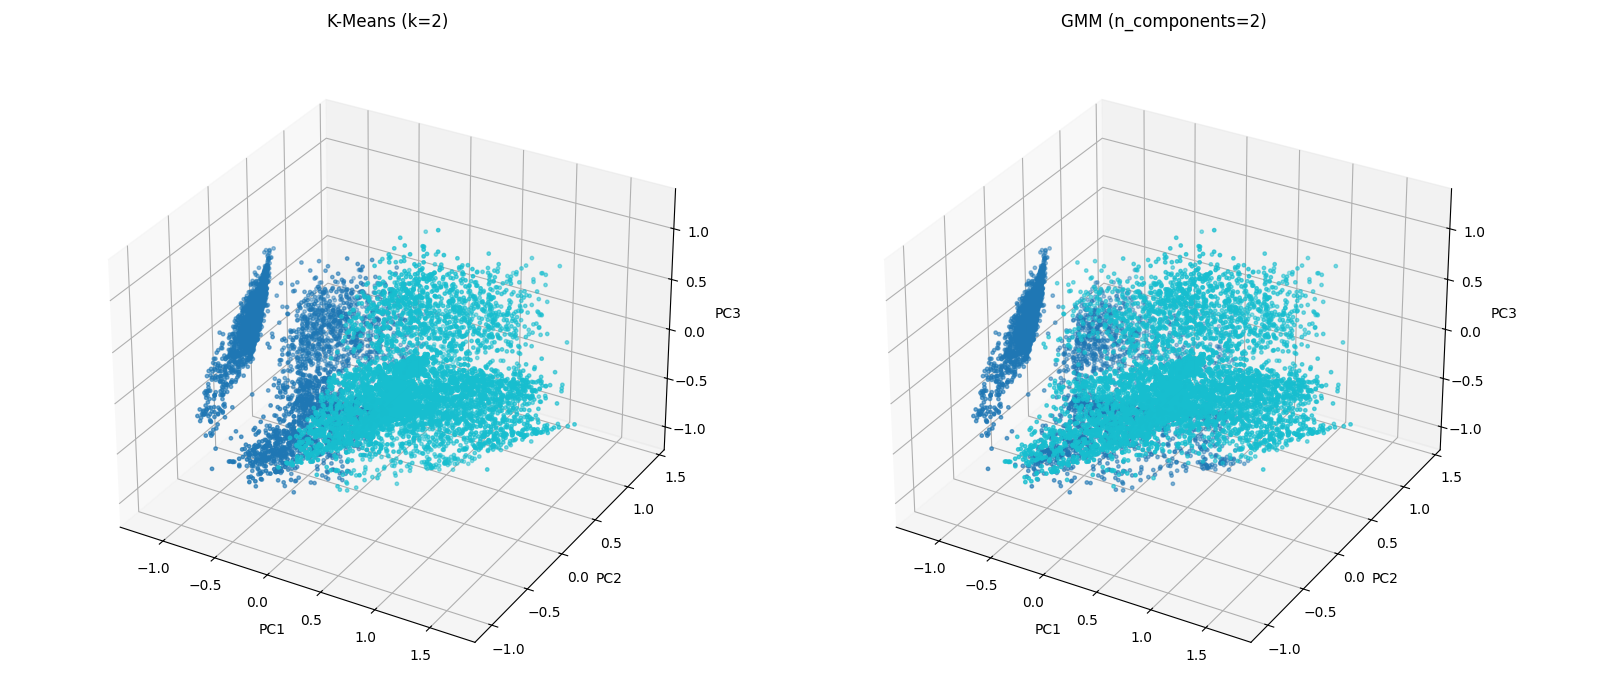

In [ ]:
kmeans_silhouette = silhouette_score(cc_scaled, kmeans_labels)
kmeans_davies_bouldin = davies_bouldin_score(cc_scaled, kmeans_labels)
gmm_silhouette = silhouette_score(cc_scaled, gmm_labels)
gmm_davies_bouldin = davies_bouldin_score(cc_scaled, gmm_labels)

print(f"K-Means (k={best_kmeans_k}): silhouette={kmeans_silhouette:.4f}, davies_bouldin={kmeans_davies_bouldin:.4f}")
print(f"GMM (n_components={best_gmm_k}): silhouette={gmm_silhouette:.4f}, davies_bouldin={gmm_davies_bouldin:.4f}")

fig = plt.figure(figsize=(16, 7))

ax_kmeans = fig.add_subplot(121, projection="3d")
ax_kmeans.scatter(cc_pca[:, 0], cc_pca[:, 1], cc_pca[:, 2], c=kmeans_labels, cmap="tab10", s=6)
ax_kmeans.set_title(f"K-Means (k={best_kmeans_k})")

ax_gmm = fig.add_subplot(122, projection="3d")
ax_gmm.scatter(cc_pca[:, 0], cc_pca[:, 1], cc_pca[:, 2], c=gmm_labels, cmap="tab10", s=6)
ax_gmm.set_title(f"GMM (n_components={best_gmm_k})")

for axis in (ax_kmeans, ax_gmm):
    axis.set_xlabel("PC1")
    axis.set_ylabel("PC2")
    axis.set_zlabel("PC3", labelpad=6)
    axis.set_box_aspect(None, zoom=0.95)

plt.subplots_adjust(left=0.0, right=0.97, bottom=0.0, top=0.95, wspace=0.0)
plt.show()

K-Means memperoleh Silhouette Score sebesar 0,3234 dan Davies-Bouldin Index sebesar 1,2661, lebih baik daripada GMM yang masing-masing memperoleh 0,2914 dan 1,3824. Hasil ini menunjukkan bahwa pembagian K-Means lebih jelas menurut kedua ukuran tersebut, meskipun pemisahan antar-cluster belum sangat kuat. Grafik tiga dimensi membantu melihat pola pembagiannya, tetapi hanya merangkum sekitar 75% variasi data sehingga tidak menampilkan seluruh perbedaan antar nasabah.


In [ ]:
kmeans_profile = cc_imputed.assign(cluster=kmeans_labels).groupby("cluster").mean().round(2)
gmm_profile = cc_imputed.assign(cluster=gmm_labels).groupby("cluster").mean().round(2)

print("K-Means cluster profile")
display(kmeans_profile.T)
print("GMM cluster profile")
display(gmm_profile.T)

gmm_confidence = gmm_model.predict_proba(cc_scaled).max(axis=1)
print("Mean GMM membership probability:", round(gmm_confidence.mean(), 4))
print("Adjusted Rand Index K-Means vs GMM:", round(adjusted_rand_score(kmeans_labels, gmm_labels), 4))
display(pd.crosstab(kmeans_labels, gmm_labels, rownames=["K-Means"], colnames=["GMM"]))

K-Means cluster profile


cluster,0,1
BALANCE,1808.00,1346.03
BALANCE_FREQUENCY,0.83,0.92
PURCHASES,233.36,1693.75
ONEOFF_PURCHASES,210.79,934.78
INSTALLMENTS_PURCHASES,22.72,759.41
CASH_ADVANCE,1498.56,512.71
PURCHASES_FREQUENCY,0.11,0.83
ONEOFF_PURCHASES_FREQUENCY,0.08,0.31
PURCHASES_INSTALLMENTS_FREQUENCY,0.03,0.66
CASH_ADVANCE_FREQUENCY,0.21,0.07


GMM cluster profile


cluster,0,1
BALANCE,1808.94,1374.65
BALANCE_FREQUENCY,0.86,0.89
PURCHASES,376.74,1489.65
ONEOFF_PURCHASES,376.74,759.93
INSTALLMENTS_PURCHASES,0.00,730.26
CASH_ADVANCE,1454.60,609.47
PURCHASES_FREQUENCY,0.15,0.75
ONEOFF_PURCHASES_FREQUENCY,0.15,0.24
PURCHASES_INSTALLMENTS_FREQUENCY,0.00,0.65
CASH_ADVANCE_FREQUENCY,0.20,0.08


Mean GMM membership probability: 1.0
Adjusted Rand Index K-Means vs GMM: 0.5857


GMM,0,1
K-Means,,
0,3547,685
1,365,4353


Pada K-Means, nasabah terbagi menjadi dua profil perilaku:
* Cluster 0 (Nasabah Penarik Tunai): Cenderung jarang berbelanja (rata-rata belanja hanya 233,36), tetapi lebih banyak memanfaatkan kartu untuk menarik uang tunai (rata-rata penarikan 1.498,56). Pada model GMM, kelompok ini bahkan tidak memiliki riwayat transaksi cicilan.
* Cluster 1 (Nasabah Pembelanja Aktif): Sangat aktif berbelanja menggunakan kartu (rata-rata belanja mencapai 1.693,75) dengan penarikan tunai yang jauh lebih sedikit (rata-rata 512,71). Pada model GMM, kelompok ini juga aktif menggunakan fasilitas cicilan dengan rata-rata 730,26.

Adjusted Rand Index antara kedua model adalah 0,5857 pada skala dengan nilai 1 untuk pembagian yang sama persis, sehingga hasilnya cukup sejalan tetapi tetap berbeda untuk sebagian nasabah. Rata-rata membership probability GMM ditampilkan sebagai 1,0000 setelah pembulatan; angka ini menggambarkan keyakinan model terhadap pembagiannya sendiri dan belum membuktikan bahwa cluster tersebut paling tepat.


### A6. Kesimpulan

Pada data Credit Card, dua cluster menjadi pilihan terbaik bagi K-Means dan GMM di antara jumlah cluster yang diuji. K-Means lebih baik menurut kedua ukuran penilaian, dengan Silhouette Score 0,3234 dan Davies-Bouldin Index 1,2661. Pembagiannya menggambarkan dua pola utama, yaitu nasabah yang lebih banyak menggunakan penarikan tunai dan nasabah yang lebih aktif berbelanja, termasuk melalui cicilan. GMM menemukan pola yang mirip, tetapi memberikan pembagian anggota yang berbeda. Hasil ini berguna sebagai gambaran awal perilaku nasabah, namun dua cluster masih cukup umum dan belum tentu mewakili seluruh kebiasaan penggunaan kartu.


## Part B: NYSE (Agglomerative Clustering dan DBSCAN)

### B1. Mengunduh dataset

In [ ]:
nyse_dir = kagglehub.dataset_download("dgawlik/nyse")
nyse_prices = pd.read_csv(os.path.join(nyse_dir, "prices-split-adjusted.csv"), parse_dates=["date"])
nyse_securities = pd.read_csv(os.path.join(nyse_dir, "securities.csv"))

print(os.listdir(nyse_dir))
print(nyse_prices.shape, nyse_securities.shape)
print(nyse_prices["date"].min(), nyse_prices["date"].max(), nyse_prices["symbol"].nunique())
display(nyse_prices.head())
display(nyse_securities.head())

Using Colab cache for faster access to the 'nyse' dataset.
['prices-split-adjusted.csv', 'fundamentals.csv', 'prices.csv', 'securities.csv']
(851264, 7) (505, 8)
2010-01-04 00:00:00 2016-12-30 00:00:00 501


,date,symbol,open,close,low,high,volume
0,2016-01-05,WLTW,123.430000,125.839996,122.309998,126.250000,2163600.0
1,2016-01-06,WLTW,125.239998,119.980003,119.940002,125.540001,2386400.0
2,2016-01-07,WLTW,116.379997,114.949997,114.930000,119.739998,2489500.0
3,2016-01-08,WLTW,115.480003,116.620003,113.500000,117.440002,2006300.0
4,2016-01-11,WLTW,117.010002,114.970001,114.089996,117.330002,1408600.0


,Ticker symbol,Security,SEC filings,GICS Sector,GICS Sub Industry,Address of Headquarters,Date first added,CIK
0,MMM,3M Company,reports,Industrials,Industrial Conglomerates,"St. Paul, Minnesota",NaN,66740
1,ABT,Abbott Laboratories,reports,Health Care,Health Care Equipment,"North Chicago, Illinois",1964-03-31,1800
2,ABBV,AbbVie,reports,Health Care,Pharmaceuticals,"North Chicago, Illinois",2012-12-31,1551152
3,ACN,Accenture plc,reports,Information Technology,IT Consulting & Other Services,"Dublin, Ireland",2011-07-06,1467373
4,ATVI,Activision Blizzard,reports,Information Technology,Home Entertainment Software,"Santa Monica, California",2015-08-31,718877


Analisis NYSE menggunakan data harga saham harian yang sudah disesuaikan terhadap stock split serta tabel informasi perusahaan dan sektornya. Karena satu saham memiliki banyak catatan harian, data ini perlu diringkas terlebih dahulu agar setiap saham dapat dibandingkan berdasarkan perilaku harganya selama periode pengamatan.


### B2. Memproses data agar bersih

In [ ]:
print(nyse_prices.isnull().sum().sum())
nyse_securities.columns = nyse_securities.columns.str.strip().str.lower().str.replace(" ", "_")
print(nyse_securities.columns.tolist())

nyse_days_per_symbol = nyse_prices.groupby("symbol")["date"].count()
nyse_min_days = 0.9 * nyse_days_per_symbol.max()
nyse_kept_symbols = nyse_days_per_symbol[nyse_days_per_symbol >= nyse_min_days].index
nyse_filtered = nyse_prices[nyse_prices["symbol"].isin(nyse_kept_symbols)]
nyse_filtered = nyse_filtered.sort_values(["symbol", "date"]).reset_index(drop=True)
print("Symbols before and after filter:", len(nyse_days_per_symbol), len(nyse_kept_symbols))

nyse_filtered["daily_return"] = nyse_filtered.groupby("symbol")["close"].pct_change()
nyse_filtered["range_ratio"] = (nyse_filtered["high"] - nyse_filtered["low"]) / nyse_filtered["close"]
nyse_filtered["running_max_close"] = nyse_filtered.groupby("symbol")["close"].cummax()
nyse_filtered["drawdown"] = nyse_filtered["close"] / nyse_filtered["running_max_close"] - 1
nyse_filtered["log_volume"] = np.log1p(nyse_filtered["volume"])
nyse_filtered["log_close"] = np.log(nyse_filtered["close"])

nyse_features = nyse_filtered.groupby("symbol").agg(
    mean_return=("daily_return", "mean"),
    volatility=("daily_return", "std"),
    max_drawdown=("drawdown", "min"),
    mean_log_volume=("log_volume", "mean"),
    mean_log_close=("log_close", "mean"),
    mean_range_ratio=("range_ratio", "mean"),
)
nyse_features = nyse_features.dropna()
display(nyse_features.describe().T.round(4))

nyse_sector = nyse_securities.set_index("ticker_symbol")["gics_sector"].reindex(nyse_features.index)
print("Stocks without sector:", nyse_sector.isnull().sum())

nyse_scaler = MinMaxScaler()
nyse_scaled = nyse_scaler.fit_transform(nyse_features)

nyse_pca_model = PCA(n_components=3, random_state=0)
nyse_pca = nyse_pca_model.fit_transform(nyse_scaled)

print(nyse_scaled.shape)
print(nyse_pca_model.explained_variance_ratio_.round(3))

0
['ticker_symbol', 'security', 'sec_filings', 'gics_sector', 'gics_sub_industry', 'address_of_headquarters', 'date_first_added', 'cik']
Symbols before and after filter: 501 469


,count,mean,std,min,25%,50%,75%,max
mean_return,469.0,0.0006,0.0003,-0.0006,0.0004,0.0006,0.0008,0.0022
volatility,469.0,0.0172,0.0051,0.0089,0.0136,0.0164,0.0198,0.0541
max_drawdown,469.0,-0.4063,0.1634,-0.9528,-0.4910,-0.3812,-0.2825,-0.1313
mean_log_volume,469.0,14.7782,0.9914,11.9919,14.1158,14.6954,15.3343,18.6160
mean_log_close,469.0,3.8819,0.6452,1.7175,3.5275,3.8865,4.2502,6.6255
mean_range_ratio,469.0,0.0212,0.0055,0.0117,0.0172,0.0204,0.0240,0.0420


Stocks without sector: 0
(469, 6)
[0.577 0.206 0.121]


Pada tahap preprocessing, data harga diperiksa kelengkapannya dan saham dengan jumlah hari pengamatan kurang dari 90% riwayat terpanjang dikeluarkan agar perbandingannya lebih sebanding. Setiap saham diringkas menjadi enam fitur: mean return, volatility, max drawdown, mean log volume, mean log close, dan mean range ratio. Fitur tersebut menggambarkan perubahan harga, besar naik-turunnya harga, penurunan terdalam dari puncak sebelumnya, volume perdagangan, tingkat harga, dan rentang harga harian. MinMaxScaler menyamakan skala fitur sebelum clustering, sedangkan sektor hanya digunakan sebagai pembanding hasil. PCA dengan tiga komponen digunakan untuk visualisasi.

### B3. Mencari nilai K

,k,silhouette,davies_bouldin
0,2,0.4041,1.0316
1,3,0.2178,1.3773
2,4,0.2068,1.3952
3,5,0.1946,1.2680
4,6,0.2011,1.2424
5,7,0.1919,1.1740
6,8,0.1887,1.2083
7,9,0.1607,1.3691
8,10,0.1433,1.3411


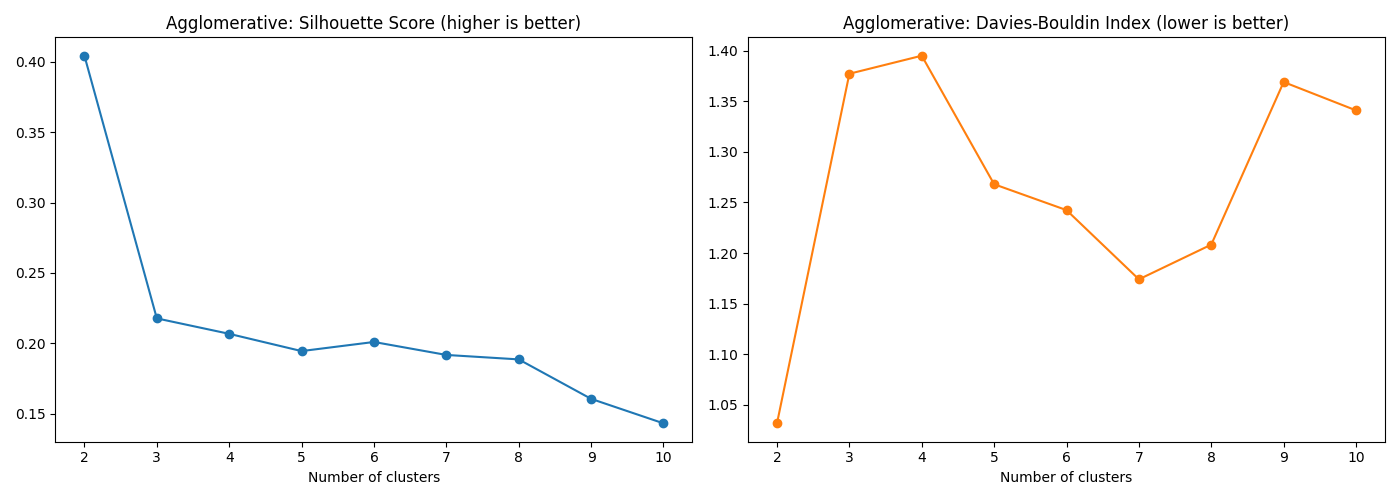

Best Agglomerative k: 2


In [ ]:
agglo_k_values = range(2, 11)

agglo_silhouette_scores = []
agglo_davies_bouldin_scores = []

for k in agglo_k_values:
    agglo_candidate = AgglomerativeClustering(n_clusters=k, linkage="complete")
    agglo_candidate_labels = agglo_candidate.fit_predict(nyse_scaled)
    agglo_silhouette_scores.append(silhouette_score(nyse_scaled, agglo_candidate_labels))
    agglo_davies_bouldin_scores.append(davies_bouldin_score(nyse_scaled, agglo_candidate_labels))

nyse_agglo_search = pd.DataFrame()
nyse_agglo_search["k"] = list(agglo_k_values)
nyse_agglo_search["silhouette"] = agglo_silhouette_scores
nyse_agglo_search["davies_bouldin"] = agglo_davies_bouldin_scores
display(nyse_agglo_search.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(agglo_k_values, agglo_silhouette_scores, marker="o")
axes[0].set_title("Agglomerative: Silhouette Score (higher is better)")
axes[1].plot(agglo_k_values, agglo_davies_bouldin_scores, marker="o", color="tab:orange")
axes[1].set_title("Agglomerative: Davies-Bouldin Index (lower is better)")
for axis in axes:
    axis.set_xlabel("Number of clusters")
plt.tight_layout()
plt.show()

best_agglo_k = agglo_k_values[np.argmin(agglo_davies_bouldin_scores)]
print("Best Agglomerative k:", best_agglo_k)

agglo_model = AgglomerativeClustering(n_clusters=best_agglo_k, linkage="complete")

Agglomerative dicoba dengan jumlah cluster antara 2 hingga 10, lalu pilihan akhirnya ditentukan dari Davies-Bouldin Index terendah. Dua cluster memberikan nilai terbaik, yaitu 1,0316, dan juga memiliki Silhouette Score tertinggi sebesar 0,4041. Kedua ukuran ini mendukung pembagian dua cluster dibandingkan pilihan lain yang diuji, sehingga pengaturan tersebut digunakan untuk proses berikutnya.


[0.04   0.045  0.05   0.055  0.06   0.065  0.07   0.075  0.08   0.085
 0.09   0.095  0.1    0.105  0.11   0.115  0.12   0.125  0.13   0.135
 0.14   0.145  0.15   0.155  0.16   0.165  0.17   0.175  0.18   0.185
 0.19   0.195  0.1997 0.2    0.205  0.21   0.215  0.22   0.225  0.23
 0.2338 0.235  0.24   0.245  0.25   0.2558 0.3111 0.4248]


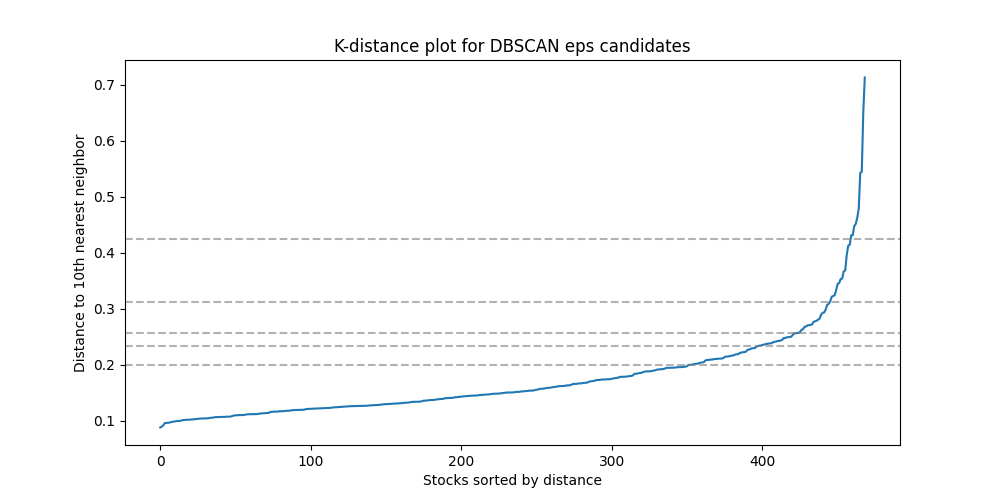

Total settings: 336
Settings with valid scores: 95
Settings without scores (fewer than 2 clusters): 241
Top 10 scored settings with noise <= 10% (full results: nyse_dbscan_search)


,eps,min_samples,n_clusters,noise_ratio,silhouette,davies_bouldin
308,0.2500,3,2,0.0277,0.5358,0.4771
309,0.2500,4,2,0.0277,0.5358,0.4771
315,0.2558,3,2,0.0277,0.5358,0.4771
316,0.2558,4,2,0.0277,0.5358,0.4771
322,0.3111,3,2,0.0064,0.5227,0.4872
323,0.3111,4,2,0.0064,0.5227,0.4872
266,0.2250,3,2,0.0405,0.5213,0.4392
273,0.2300,3,2,0.0384,0.5207,0.4397
280,0.2338,3,2,0.0384,0.5207,0.4397
287,0.2350,3,2,0.0384,0.5207,0.4397


Best DBSCAN eps: 0.25 min_samples: 3


In [ ]:
neighbors = NearestNeighbors(n_neighbors=10).fit(nyse_scaled)
neighbor_distances, _ = neighbors.kneighbors(nyse_scaled)
kdistance = np.sort(neighbor_distances[:, -1])

distance_quantiles = np.quantile(
    kdistance, [0.75, 0.85, 0.90, 0.95, 0.98]
).round(4)

eps_candidates = np.unique(
    np.concatenate([
        np.arange(0.04, 0.251, 0.005).round(4),
        distance_quantiles,
    ])
)
min_samples_candidates = [3, 4, 5, 8, 10, 12, 15]
print(eps_candidates)

plt.figure(figsize=(10, 5))
plt.plot(kdistance)
for eps_value in distance_quantiles:
    plt.axhline(
        eps_value, linestyle="--", color="gray", alpha=0.6
    )
plt.xlabel("Stocks sorted by distance")
plt.ylabel("Distance to 10th nearest neighbor")
plt.title("K-distance plot for DBSCAN eps candidates")
plt.show()

grid_eps = []
grid_min_samples = []
grid_n_clusters = []
grid_noise_ratio = []
grid_silhouette = []
grid_davies_bouldin = []

for eps_value in eps_candidates:
    for min_samples_value in min_samples_candidates:
        candidate_labels = DBSCAN(
            eps=eps_value,
            min_samples=min_samples_value,
        ).fit_predict(nyse_scaled)

        candidate_non_noise = candidate_labels != -1
        candidate_cluster_count = len(
            set(candidate_labels[candidate_non_noise])
        )

        candidate_silhouette = np.nan
        candidate_davies_bouldin = np.nan

        if 2 <= candidate_cluster_count < candidate_non_noise.sum():
            candidate_silhouette = silhouette_score(
                nyse_scaled[candidate_non_noise],
                candidate_labels[candidate_non_noise],
            )
            candidate_davies_bouldin = davies_bouldin_score(
                nyse_scaled[candidate_non_noise],
                candidate_labels[candidate_non_noise],
            )

        grid_eps.append(eps_value)
        grid_min_samples.append(min_samples_value)
        grid_n_clusters.append(candidate_cluster_count)
        grid_noise_ratio.append(1 - candidate_non_noise.mean())
        grid_silhouette.append(candidate_silhouette)
        grid_davies_bouldin.append(candidate_davies_bouldin)

nyse_dbscan_search = pd.DataFrame()
nyse_dbscan_search["eps"] = grid_eps
nyse_dbscan_search["min_samples"] = grid_min_samples
nyse_dbscan_search["n_clusters"] = grid_n_clusters
nyse_dbscan_search["noise_ratio"] = grid_noise_ratio
nyse_dbscan_search["silhouette"] = grid_silhouette
nyse_dbscan_search["davies_bouldin"] = grid_davies_bouldin

scored_settings = nyse_dbscan_search.dropna(
    subset=["silhouette", "davies_bouldin"]
)

print("Total settings:", len(nyse_dbscan_search))
print("Settings with valid scores:", len(scored_settings))
print(
    "Settings without scores (fewer than 2 clusters):",
    len(nyse_dbscan_search) - len(scored_settings),
)
print(
    "Top 10 scored settings with noise <= 10% "
    "(full results: nyse_dbscan_search)"
)

display(
    scored_settings[scored_settings["noise_ratio"] <= 0.1]
    .sort_values(
        ["silhouette", "eps", "min_samples"],
        ascending=[False, True, True],
    )
    .head(10)
    .round(4)
)

max_noise_ratio = 0.1

dbscan_valid = nyse_dbscan_search[
    nyse_dbscan_search["silhouette"].notna()
    & (nyse_dbscan_search["noise_ratio"] <= max_noise_ratio)
]

if dbscan_valid.empty:
    print(
        "No setting met the noise limit, "
        "using all settings with 2 or more clusters"
    )
    dbscan_valid = scored_settings

if dbscan_valid.empty:
    raise ValueError(
        "No setting produced valid scores; "
        "revise the parameter range before selecting a model."
    )

best_dbscan = dbscan_valid.sort_values(
    ["silhouette", "eps", "min_samples"],
    ascending=[False, True, True],
).iloc[0]

best_eps = float(best_dbscan["eps"])
best_min_samples = int(best_dbscan["min_samples"])

print(
    "Best DBSCAN eps:", best_eps,
    "min_samples:", best_min_samples,
)

dbscan_model = DBSCAN(
    eps=best_eps,
    min_samples=best_min_samples,
)

DBSCAN diuji menggunakan 336 kombinasi eps dan min_samples. Dari seluruh percobaan, 95 kombinasi menghasilkan skor yang dapat dihitung, sedangkan kombinasi lainnya menghasilkan kurang dari dua cluster. Pemilihan parameter mengutamakan Silhouette Score tertinggi dengan noise maksimal 10%. Hasil terpilih adalah eps 0,25 dan min_samples 3, yang menghasilkan dua cluster berisi 452 dan 4 saham serta 13 saham noise atau sekitar 2,77%. Meskipun skornya lebih baik, ukuran cluster yang sangat berbeda perlu diperhatikan saat menilai kegunaan hasilnya.

### B4. Melatih model

In [ ]:
agglo_labels = agglo_model.fit_predict(nyse_scaled)
dbscan_labels = dbscan_model.fit_predict(nyse_scaled)

print("Agglomerative cluster sizes")
print(pd.Series(agglo_labels).value_counts().sort_index())
print("DBSCAN cluster sizes (-1 is noise)")
print(pd.Series(dbscan_labels).value_counts().sort_index())

Agglomerative cluster sizes
0    406
1     63
Name: count, dtype: int64
DBSCAN cluster sizes (-1 is noise)
-1     13
 0    452
 1      4
Name: count, dtype: int64


Dari 469 saham yang dianalisis, Agglomerative membentuk dua cluster dengan anggota 406 dan 63 saham. DBSCAN menghasilkan satu cluster utama berisi 435 saham, sedangkan 34 saham lainnya, atau sekitar 7,25%, ditandai sebagai noise dengan label -1 karena tidak memenuhi syarat untuk bergabung ke cluster. Label tersebut menunjukkan perbedaan pola pada fitur yang digunakan dan tidak berarti sahamnya buruk.


### B5. Mengevaluasi model

Agglomerative (k=2): silhouette=0.4041, davies_bouldin=1.0316
DBSCAN (eps=0.25, min_samples=3): clusters=2, noise_ratio=0.0277, silhouette=0.5358, davies_bouldin=0.4771


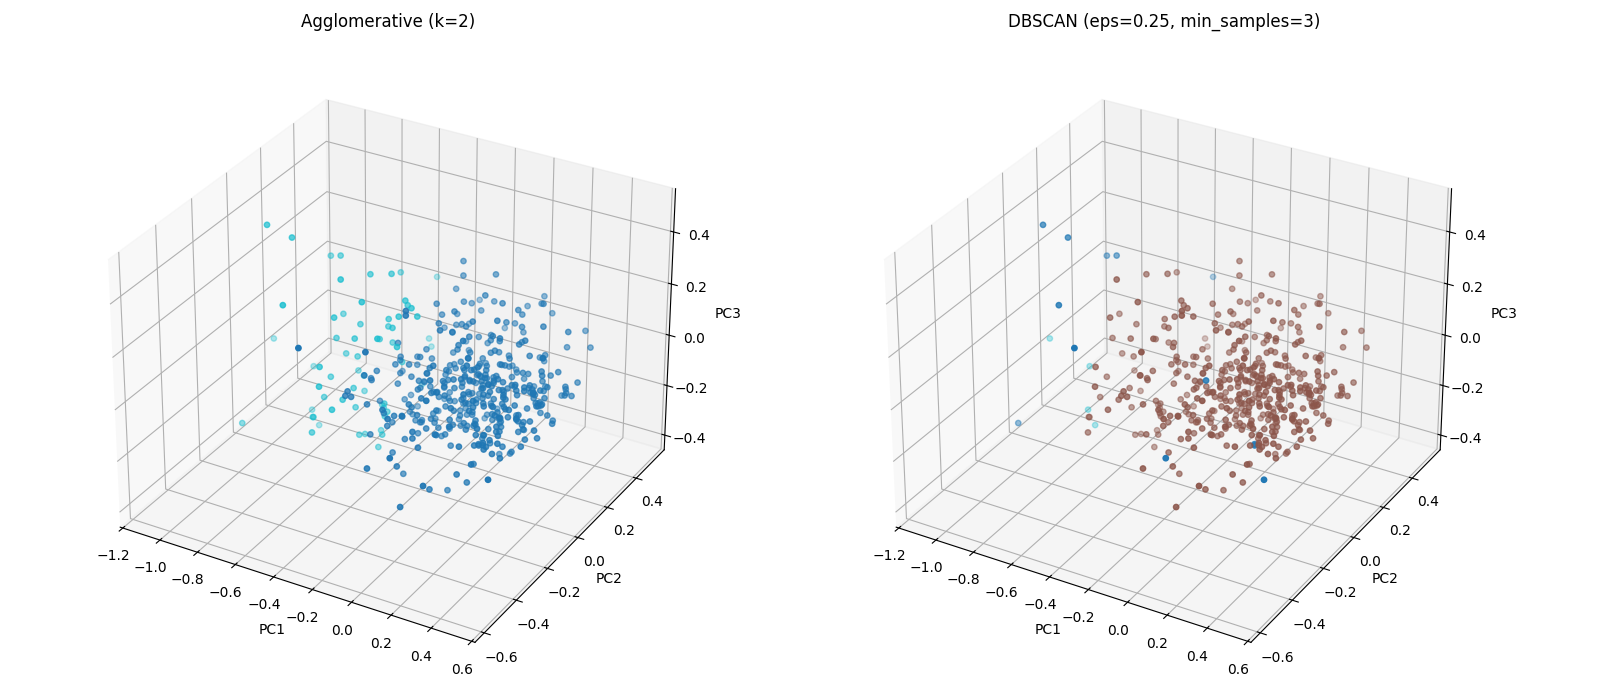

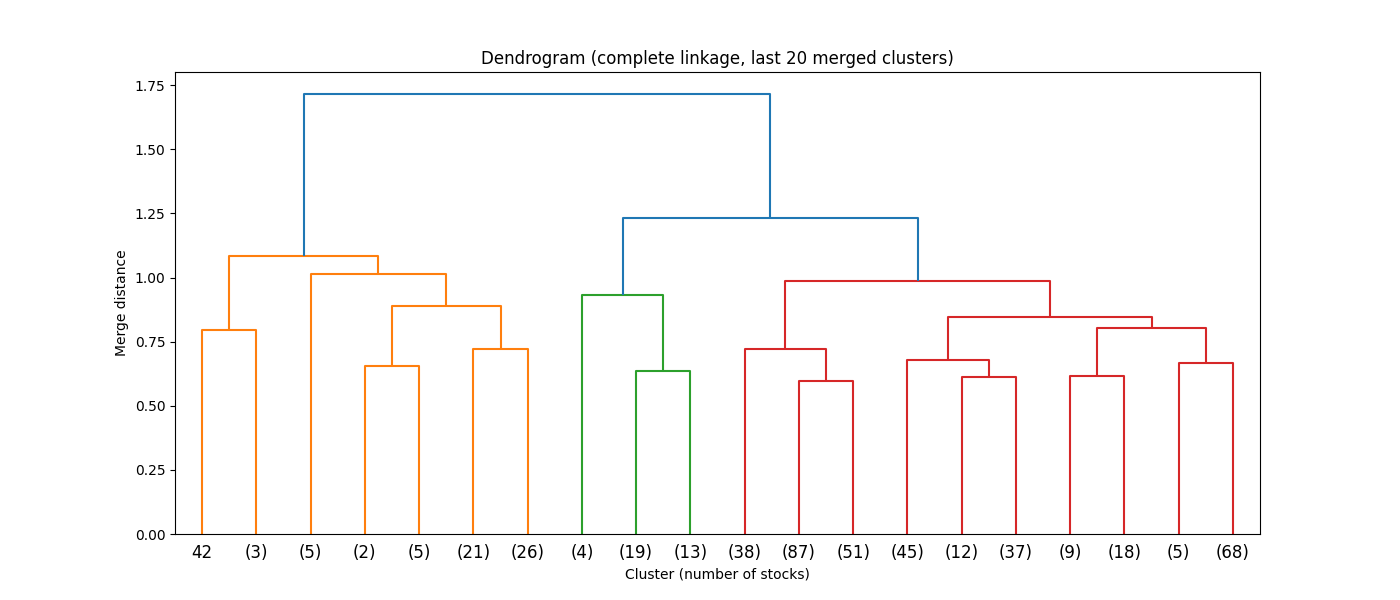

In [ ]:
agglo_silhouette = silhouette_score(nyse_scaled, agglo_labels)
agglo_davies_bouldin = davies_bouldin_score(nyse_scaled, agglo_labels)

dbscan_non_noise = dbscan_labels != -1
dbscan_cluster_count = len(set(dbscan_labels[dbscan_non_noise]))
dbscan_noise_ratio = 1 - dbscan_non_noise.mean()
dbscan_silhouette = np.nan
dbscan_davies_bouldin = np.nan
if dbscan_cluster_count >= 2:
    dbscan_silhouette = silhouette_score(nyse_scaled[dbscan_non_noise], dbscan_labels[dbscan_non_noise])
    dbscan_davies_bouldin = davies_bouldin_score(nyse_scaled[dbscan_non_noise], dbscan_labels[dbscan_non_noise])

print(f"Agglomerative (k={best_agglo_k}): silhouette={agglo_silhouette:.4f}, davies_bouldin={agglo_davies_bouldin:.4f}")
print(f"DBSCAN (eps={best_eps}, min_samples={best_min_samples}): clusters={dbscan_cluster_count}, noise_ratio={dbscan_noise_ratio:.4f}, silhouette={dbscan_silhouette:.4f}, davies_bouldin={dbscan_davies_bouldin:.4f}")

fig = plt.figure(figsize=(16, 7))

ax_agglo = fig.add_subplot(121, projection="3d")
ax_agglo.scatter(nyse_pca[:, 0], nyse_pca[:, 1], nyse_pca[:, 2], c=agglo_labels, cmap="tab10", s=15)
ax_agglo.set_title(f"Agglomerative (k={best_agglo_k})")

ax_dbscan = fig.add_subplot(122, projection="3d")
ax_dbscan.scatter(nyse_pca[:, 0], nyse_pca[:, 1], nyse_pca[:, 2], c=dbscan_labels, cmap="tab10", s=15)
ax_dbscan.set_title(f"DBSCAN (eps={best_eps}, min_samples={best_min_samples})")

for axis in (ax_agglo, ax_dbscan):
    axis.set_xlabel("PC1")
    axis.set_ylabel("PC2")
    axis.set_zlabel("PC3", labelpad=6)
    axis.set_box_aspect(None, zoom=0.95)

plt.subplots_adjust(left=0.0, right=0.97, bottom=0.0, top=0.95, wspace=0.0)
plt.show()

nyse_linkage = linkage(nyse_scaled, method="complete")

plt.figure(figsize=(14, 6))
dendrogram(nyse_linkage, truncate_mode="lastp", p=20, show_leaf_counts=True)
plt.title("Dendrogram (complete linkage, last 20 merged clusters)")
plt.xlabel("Cluster (number of stocks)")
plt.ylabel("Merge distance")
plt.show()

Agglomerative memperoleh Silhouette Score 0,4041 dan Davies-Bouldin Index 1,0316 untuk pembagian dua cluster. Pada DBSCAN, kedua skor ditampilkan sebagai NaN karena hanya ada satu cluster setelah 34 noise dikeluarkan dari penilaian. Karena itu, hasil DBSCAN belum dapat dibandingkan langsung dengan Agglomerative melalui kedua skor ini. Grafik tiga dimensi merangkum sekitar 90,4% variasi data untuk membantu melihat sebaran saham, sedangkan dendrogram menunjukkan tahap penggabungan cluster dan jarak saat penggabungan terjadi.


In [ ]:
agglo_profile = nyse_features.assign(cluster=agglo_labels).groupby("cluster").mean().round(4)
dbscan_profile = nyse_features.assign(cluster=dbscan_labels).groupby("cluster").mean().round(4)

print("Agglomerative cluster profile")
display(agglo_profile.T)
print("DBSCAN cluster profile (-1 is noise)")
display(dbscan_profile.T)

nyse_result = nyse_features.copy()
nyse_result["sector"] = nyse_sector
nyse_result["agglomerative"] = agglo_labels
nyse_result["dbscan"] = dbscan_labels
nyse_result = nyse_result.dropna(subset=["sector"])

print("Adjusted Rand Index vs sector, Agglomerative:", round(adjusted_rand_score(nyse_result["sector"], nyse_result["agglomerative"]), 4))
print("Adjusted Rand Index vs sector, DBSCAN:", round(adjusted_rand_score(nyse_result["sector"], nyse_result["dbscan"]), 4))
display(pd.crosstab(nyse_result["sector"], nyse_result["agglomerative"]))
display(pd.crosstab(nyse_result["sector"], nyse_result["dbscan"]))

noise_symbols = nyse_features.index[dbscan_labels == -1]
print("Stocks labeled as noise:", len(noise_symbols))
display(nyse_features.loc[noise_symbols].join(nyse_sector))

Agglomerative cluster profile


cluster,0,1
mean_return,0.0006,0.0006
volatility,0.0158,0.0259
max_drawdown,-0.3643,-0.6768
mean_log_volume,14.6753,15.4416
mean_log_close,3.9479,3.4569
mean_range_ratio,0.0197,0.0310


DBSCAN cluster profile (-1 is noise)


cluster,-1,0,1
mean_return,0.0011,0.0006,-0.0003
volatility,0.0272,0.0168,0.0320
max_drawdown,-0.5392,-0.3978,-0.9259
mean_log_volume,15.2984,14.7510,16.1583
mean_log_close,4.3948,3.8728,3.2417
mean_range_ratio,0.0293,0.0208,0.0374


Adjusted Rand Index vs sector, Agglomerative: 0.0136
Adjusted Rand Index vs sector, DBSCAN: -0.0013


agglomerative,0,1
sector,,
Consumer Discretionary,70,8
Consumer Staples,33,1
Energy,12,21
Financials,54,4
Health Care,50,4
Industrials,57,6
Information Technology,52,11
Materials,19,5
Real Estate,29,0


dbscan,-1,0,1
sector,,,
Consumer Discretionary,3,75,0
Consumer Staples,0,34,0
Energy,0,30,3
Financials,1,57,0
Health Care,1,53,0
Industrials,3,60,0
Information Technology,5,58,0
Materials,0,23,1
Real Estate,0,29,0


Stocks labeled as noise: 13


,mean_return,volatility,max_drawdown,mean_log_volume,mean_log_close,mean_range_ratio,gics_sector
symbol,,,,,,,
AAL,0.001764,0.030713,-0.668600,15.913388,2.915724,0.039968,Industrials
AMZN,0.001186,0.020395,-0.305345,15.201329,5.681184,0.023979,Consumer Discretionary
ARNC,0.001020,0.054064,-0.628240,16.088359,2.153913,0.027457,Industrials
AZO,0.000978,0.011321,-0.131292,12.653006,6.055152,0.016500,Consumer Discretionary
BAC,0.000449,0.022519,-0.743840,18.615964,2.566430,0.024746,Financials
FSLR,-0.000157,0.036659,-0.931089,14.842072,4.025251,0.042021,Information Technology
GOOG,0.000637,0.015737,-0.304236,14.992764,6.057756,0.017379,Information Technology
GOOGL,0.000648,0.015685,-0.304236,15.029667,6.070410,0.017450,Information Technology
MU,0.000874,0.030834,-0.738010,17.172603,2.526171,0.037737,Information Technology


Pada model Agglomerative, saham terbagi menjadi dua kelompok risiko yang jelas:
* Cluster 0 (Saham Tenang / Rendah Risiko): Pergerakan harganya stabil (rata-rata naik-turun hanya 1,58% per hari) dan penurunan terdalamnya relatif kecil (sekitar 36,43%).
* Cluster 1 (Saham Liar / Tinggi Risiko): Pergerakan harganya jauh lebih bergejolak (naik-turun 2,59% per hari) dan pernah mengalami penurunan tajam hingga 67,68%.

Saham yang diberi label noise oleh DBSCAN rata-rata memiliki pergerakan harga lebih besar dan penurunan lebih dalam daripada cluster utamanya, tetapi karakter tiap saham tetap beragam. Contohnya mencakup AAPL, AMZN, CHK, dan NFLX. Adjusted Rand Index terhadap sektor perusahaan mendekati nol, yaitu 0,0136 untuk Agglomerative dan -0,0022 untuk DBSCAN, sehingga cluster yang terbentuk lebih mencerminkan perilaku harga daripada jenis usaha.


### B6. Kesimpulan

Pada data NYSE, Agglomerative menghasilkan dua cluster berisi 406 dan 63 saham, dengan perbedaan utama pada besar pergerakan harga dan kedalaman penurunan selama pengamatan. Dendrogram melengkapi hasil ini dengan memperlihatkan proses penggabungan cluster. DBSCAN hanya menghasilkan satu cluster utama berisi 435 saham dan menandai 34 saham, termasuk AAPL, AMZN, CHK, dan NFLX, sebagai noise pada pengaturan cadangan yang digunakan. Karena tidak ada kombinasi yang diuji menghasilkan sedikitnya dua cluster utama, kualitas pembagian DBSCAN belum dapat dinilai dengan skor yang sama. Hasil kedua model juga hampir tidak sejalan dengan pembagian sektor perusahaan. Temuan ini terbatas pada ringkasan harga dan volume selama 2010–2016 serta pengaturan yang dicoba, sehingga belum mencakup kondisi keuangan perusahaan atau perubahan pola dari waktu ke waktu.

# Kesimpulan Umum

Clustering pada kedua dataset memperlihatkan bahwa hasil yang berguna bergantung pada pola data dan ukuran yang dipakai.
* Pada 8.950 nasabah Credit Card dengan 17 fitur perilaku, K-Means menghasilkan pemisahan yang lebih baik daripada GMM menurut kedua skor penilaian, dengan perbedaan utama antara penggunaan untuk belanja dan penarikan tunai.
* Pada 469 saham NYSE yang diringkas menjadi enam fitur, Agglomerative membedakan cluster dengan pergerakan harga relatif lebih kecil (stabil) dan lebih besar (agresif), sementara DBSCAN menyatukan hampir seluruh saham dalam satu cluster utama serta menandai sebagian saham yang berbeda sebagai noise.

Karena itu, penilaian perlu melihat skor, jumlah anggota, dan karakter cluster secara bersamaan.Keyakinan model atau adanya noise saja belum cukup untuk menyimpulkan bahwa hasilnya lebih baik.


